<a href="https://colab.research.google.com/github/nattaponm/Teach_HID_Doppler_KKN_summerStorm/blob/main/notebooks/01_polar_radar_variables.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 1: ตัวแปรเรดาร์แบบ polar และการตรวจคุณภาพข้อมูล
### Polar radar variables, the Doppler dilemma, beam geometry and data-quality checks

⏱️ เวลาเรียนโดยประมาณ **60–75 นาที** | ไม่มีพื้นฐานบังคับ (แนะนำให้เคยเรียน repo *Teach_Pysteps_KKN_summerStorm* NB1)

**เคสศึกษา:** พายุฤดูร้อน 3 พฤษภาคม 2567 เรดาร์ C-band แบบ dual-polarization ของกรมอุตุนิยมวิทยาที่ขอนแก่น (KKN)
ลมกระโชกแรงและลูกเห็บสร้างความเสียหายที่ อ.ภูกระดึง (14:00 น.), จ.หนองบัวลำภู (~16:30 น.), จ.หนองคาย (~17:00 น.) และ จ.ขอนแก่น/บึงกาฬ (กลางคืน)

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **อธิบายโครงสร้างข้อมูล polar volume** (sweep → ray → gate) และอ่านไฟล์ CfRadial ด้วย **Py-ART**
2. **อธิบายความหมายทางกายภาพ** ของ $Z_H$, $V_r$, $\sigma_v$, $Z_{DR}$, $\Phi_{DP}$ และ $\rho_{HV}$
3. **คำนวณ Nyquist velocity และระยะไกลสุดที่ไม่กำกวม** แล้วอธิบาย *Doppler dilemma*
4. **คำนวณความสูงของลำคลื่นเรดาร์** แล้วเทียบกับระดับ 0 °C และ −20 °C จาก sounding
5. **ตรวจคุณภาพข้อมูลเบื้องต้น** ได้แก่ qc_flag, ZDR bias, $\rho_{HV}$ ตามระยะ และการพับเฟสของ $\Phi_{DP}$

## 📖 1. แนวคิดและสมการ

### 1.1 ข้อมูลเรดาร์แบบ polar
เรดาร์หมุนรอบตัว (azimuth 0–360°) ที่มุมยก (elevation) คงที่ 1 รอบ = **sweep** หรือ PPI
แต่ละทิศทางคือ **ray** และแต่ละ ray แบ่งตามระยะเป็น **gate** (KKN: 480 gate × 500 m = 240 km)
KKN ในเคสนี้มี **4 มุมยก (0.48°, 1.48°, 2.39°, 3.39°)** ทุก 15 นาที รวมเป็น 1 **volume**

### 1.2 ตัวแปรหลัก
| สัญลักษณ์ | ชื่อ | หน่วย | บอกอะไร |
|---|---|---|---|
| $Z_H$ | reflectivity (การสะท้อนกลับ) | dBZ | ขนาดและจำนวนเม็ดน้ำ/น้ำแข็ง ($\propto \sum D^6$) |
| $V_r$ | radial velocity (ความเร็วตามแนวรัศมี) | m s⁻¹ | ลมที่วิ่ง **เข้าหา (−)** หรือ **ออกจาก (+)** เรดาร์ |
| $\sigma_v$ | spectrum width (ความกว้างสเปกตรัม) | m s⁻¹ | ความแปรปรวนของความเร็วในปริมาตรวัด → ความปั่นป่วน (NB3) |
| $Z_{DR}$ | differential reflectivity | dB | รูปร่างเม็ด: ฝนเม็ดใหญ่แบน → ค่าบวกมาก, ลูกเห็บกลิ้ง → ใกล้ 0 |
| $\Phi_{DP}$ | differential phase | ° | เฟสสะสมจากน้ำเหลว → ใช้หา $K_{DP}$ (NB4) |
| $\rho_{HV}$ | co-polar correlation coefficient | – | ความ "เหมือนกัน" ของเม็ดในปริมาตร: ฝนล้วน > 0.97, ปนลูกเห็บ/ชั้นละลาย 0.85–0.95, non-met < 0.8 |

$$ Z_{DR} = 10\log_{10}\frac{Z_H}{Z_V},\qquad K_{DP} = \frac{1}{2}\frac{d\Phi_{DP}}{dr} $$

### 1.3 หลักการ Doppler และ *Doppler dilemma*
เรดาร์วัดการเลื่อนเฟสระหว่างพัลส์ ได้ความถี่ Doppler $f_D = 2V_r/\lambda$ แต่วัดได้ไม่เกินครึ่งหนึ่งของ PRF (Nyquist)
$$ V_{ny} = \frac{\lambda\,\mathrm{PRF}}{4},\qquad r_{max} = \frac{c}{2\,\mathrm{PRF}}
\quad\Longrightarrow\quad V_{ny}\,r_{max} = \frac{c\,\lambda}{8} $$
ผลคูณคงที่ → ถ้าอยากวัด **ไกล** ต้องใช้ PRF ต่ำ → $V_{ny}$ **ต่ำ** → ลมแรงเกิน $\pm V_{ny}$ จะ **"พับ" (aliasing)** กลับมาเป็นค่าผิด
$$ V_{obs} = V_{true} - 2nV_{ny},\qquad n \in \{\dots,-1,0,1,\dots\} $$

### 1.4 ความสูงของลำคลื่น (แบบจำลองโลกรัศมี 4/3)
$$ h = \sqrt{r^2 + (k_e a)^2 + 2 r k_e a \sin\theta} - k_e a + h_0,\qquad k_e = 4/3,\ a = 6371\ \mathrm{km} $$
ความกว้างลำคลื่น $\approx r\,\Delta\theta$ (beamwidth 1°) → ที่ 120 km ลำคลื่นกว้าง ~2 km
ทำให้ "สิ่งที่เรดาร์เห็น" ไกล ๆ เป็นค่าเฉลี่ยของปริมาตรใหญ่ และอาจอยู่ **เหนือระดับเยือกแข็ง** ทั้งหมด

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–3 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_HID_Doppler_KKN_summerStorm"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q arm_pyart cartopy netCDF4 geopandas metpy cmweather rasterio
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "polar_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import polar_tools as pt
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 64.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 78.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 424.4/424.4 kB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 67.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.8/157.8 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 64.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 63.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not current

In [2]:
files = pt.polar_files(DATA)                       # 92 ไฟล์ทั้งวัน (UTC)
peak = pt.polar_files(DATA, "09:00", "10:45")       # 8 ไฟล์ช่วงพายุแรงที่หนองบัวลำภู
print(f"จำนวน volume ทั้งวัน: {len(files)} | ช่วงพีค: {len(peak)} ไฟล์")
radar = pt.read_volume(pt.polar_files(DATA, "09:30", "09:30")[0])
meta = pt.polar_meta(radar)                         # ระบบพิกัด AEQD สำหรับแผนที่
snd = pt.load_profile(os.path.join(DATA, "sounding", "sounding_48431_2024-05-03_00Z.csv"))
reports = kt.load_reports(DATA, meta)
NW = kt.box_around(meta, 102.3, 17.3, 90)           # กรอบซูม: เลย–หนองบัวลำภู–หนองคาย
H = {f"{t} °C": pt.isotherm_height(snd, t) for t in (0, -10, -20)}
print(f"เวลา: {mp.tlabel(pt.volume_time(radar))}")
print("ระดับอุณหภูมิจาก sounding 48431 (00Z):", {k: f"{v:.0f} m" for k, v in H.items()})

จำนวน volume ทั้งวัน: 92 | ช่วงพีค: 8 ไฟล์
เวลา: 09:30 UTC (16:30 LT)
ระดับอุณหภูมิจาก sounding 48431 (00Z): {'0 °C': '5172 m', '-10 °C': '6878 m', '-20 °C': '8516 m'}


## 🔍 3. โครงสร้างของ polar volume

In [3]:
print(f"sweeps = {radar.nsweeps}, rays ทั้งหมด = {radar.nrays}, gates/ray = {radar.ngates}")
print("มุมยก (°):", np.round(radar.fixed_angle["data"], 2))
print("rays ต่อ sweep:", [radar.get_slice(s).stop - radar.get_slice(s).start for s in range(radar.nsweeps)])
print(f"ระยะ gate แรก–สุดท้าย: {radar.range['data'][0]/1000:.2f}–{radar.range['data'][-1]/1000:.1f} km "
      f"(ทุก {np.diff(radar.range['data'])[0]:.0f} m)")
print(f"Nyquist velocity = {pt.nyquist(radar):.2f} m/s | ความถี่ = {pt.RADAR_FREQ_HZ/1e9:.1f} GHz (λ = {pt.WAVELENGTH_M*100:.2f} cm)")
pd.DataFrame({f: {"units": radar.fields[f].get("units", ""),
                  "valid_gates": int(np.ma.count(radar.fields[f]["data"])),
                  "min": float(np.ma.min(radar.fields[f]["data"])),
                  "max": float(np.ma.max(radar.fields[f]["data"]))} for f in radar.fields}).T

sweeps = 4, rays ทั้งหมด = 2044, gates/ray = 480
มุมยก (°): [0.48 1.48 2.39 3.39]
rays ต่อ sweep: [np.int32(511), np.int32(511), np.int32(511), np.int32(511)]
ระยะ gate แรก–สุดท้าย: 0.75–240.2 km (ทุก 500 m)
Nyquist velocity = 8.38 m/s | ความถี่ = 5.6 GHz (λ = 5.35 cm)


,units,valid_gates,min,max
reflectivity_raw,dBZ,76273,-31.5,59.0
reflectivity_qc,dBZ,56505,0.0,59.0
velocity_qc,meters_per_second,36256,-8.3,8.3
spectrum_width_qc,meters_per_second,36256,0.0,4.8
differential_reflectivity_qc,dB,56505,-12.799999,7.62
differential_phase_qc,degrees,56505,-179.600006,212.800003
cross_correlation_ratio_qc,ratio,56505,0.05,1.0
qc_flag,1,981120,0.0,112.0


`reflectivity_raw` คือ Z ก่อน QC ส่วน field ที่ลงท้าย `_qc` ผ่าน **gentle QC** แล้ว (ตัด echo < 0 dBZ, flare ray, non-met ที่ $\rho_{HV}$ < 0.7 และ Z < 25 dBZ, speckle)
**ความเร็วยังไม่ได้แก้การพับ (aliased)** — จะทำใน NB2

## 🗺️ 4. แผนที่ 6 ตัวแปร ที่มุมยกต่ำสุด (0.48°)

บันทึกรูปแล้ว: figures/nb1_six_variables.png, figures/nb1_six_variables.pdf


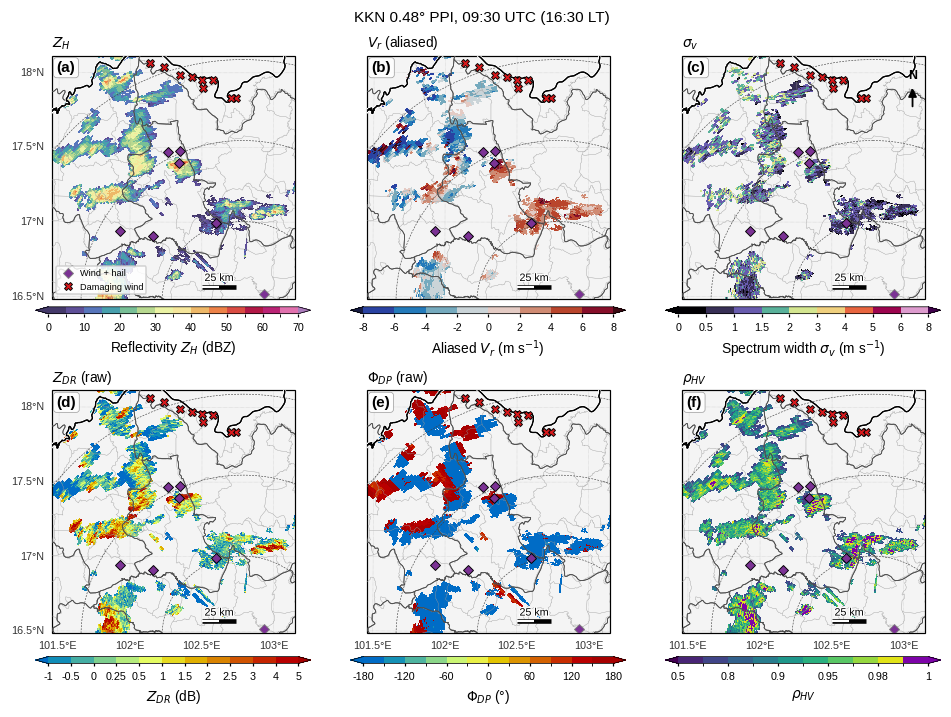

In [4]:
panels = [("reflectivity_qc", "Z", "$Z_H$"), ("velocity_qc", "VA", "$V_r$ (aliased)"),
          ("spectrum_width_qc", "W", "$\\sigma_v$"), ("differential_reflectivity_qc", "ZDR", "$Z_{DR}$ (raw)"),
          ("differential_phase_qc", "PHI", "$\\Phi_{DP}$ (raw)"), ("cross_correlation_ratio_qc", "RHO", "$\\rho_{HV}$")]
fig, axs = mp.map_panels(2, 3, meta, panel_width=2.9, zoom=NW)
for k, (ax, (f, kind, ttl)) in enumerate(zip(axs, panels)):
    im = pt.ppi_map(ax, radar, f, 0, meta, kind=kind, zoom=NW, title=ttl, north=(k == 2),
                    gridline_labels=(("left",) if k % 3 == 0 else ()) + (("bottom",) if k >= 3 else ()))
    mp.add_reports(ax, reports, legend=(k == 0))
    mp.add_colorbar(fig, im, ax, shrink=0.9, extend="both")
mp.panel_labels(axs)
fig.suptitle(f"KKN 0.48° PPI, {mp.tlabel(pt.volume_time(radar))}", fontsize=10)
mp.save_figure(fig, "nb1_six_variables")
plt.show()

**อ่านแผนที่:**
- (a) แกนพายุ $Z_H$ ≥ 45 dBZ อยู่ติดกับจุดรายงานลมกระโชก+ลูกเห็บที่ อ.นากลาง/สุวรรณคูหา (◆) และมีแถบพายุอีกแนวทางตะวันตก–ตะวันตกเฉียงเหนือ
- (b) สีน้ำเงิน = ลมเข้าหาเรดาร์, แดง = ออกจากเรดาร์ — สังเกต **สีกระโดดจากแดงเข้มเป็นน้ำเงินเข้ม** ทันที = รอยพับ (aliasing)
- (d) $Z_{DR}$ ในแกนฝนเป็นบวกสูง (เม็ดใหญ่), (e) $\Phi_{DP}$ เปลี่ยนสีวนรอบ ±180° = รอยพับเฟส, (f) $\rho_{HV}$ ต่ำที่ขอบพายุและที่ระยะไกล

## 🌀 5. Doppler dilemma ของ KKN

In [5]:
vs = pd.read_csv(os.path.join(DATA, "KKN_20240503", "KKN_20240503_volume_stats.csv"), parse_dates=["time_utc"])
vs = vs[vs["available"]]
c, lam = 2.998e8, pt.WAVELENGTH_M
tab = vs.groupby("nyquist").agg(n_volumes=("time_tag", "size"), first=("time_utc", "min"), last=("time_utc", "max"))
tab["PRF_Hz (single PRF)"] = 4 * tab.index / lam
tab["r_max_km"] = c / (2 * tab["PRF_Hz (single PRF)"]) / 1000
tab.round(1)

,n_volumes,first,last,PRF_Hz (single PRF),r_max_km
nyquist,,,,,
8.38,77,2024-05-03 03:30:00,2024-05-03 23:45:00,626.1,239.4
16.75,14,2024-05-03 00:00:00,2024-05-03 03:15:00,1251.5,119.8


บันทึกรูปแล้ว: figures/nb1_nyquist.png, figures/nb1_nyquist.pdf


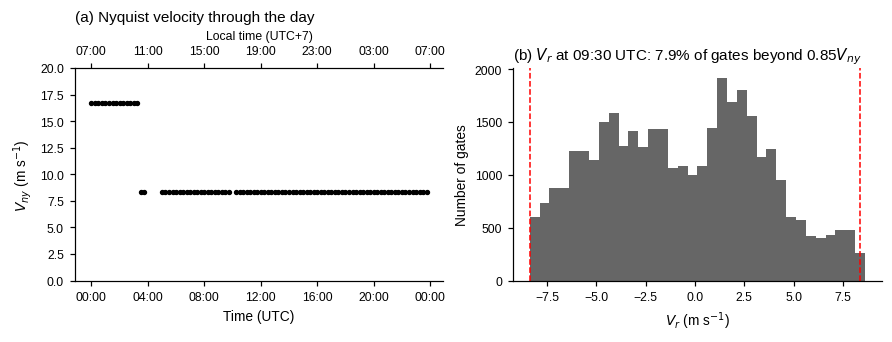

In [6]:
v = pt.field_data(radar, "velocity_qc")
vny = pt.nyquist(radar)
fig, axs = plt.subplots(1, 2, figsize=(8, 3), layout="constrained")
axs[0].plot(vs["time_utc"], vs["nyquist"], "o", ms=2.5, color="k")
axs[0].set_ylabel("$V_{ny}$ (m s$^{-1}$)"); mp.time_axis(axs[0], interval_h=4)
axs[0].set_ylim(0, 20); axs[0].set_title("(a) Nyquist velocity through the day", loc="left")
axs[1].hist(v[np.isfinite(v)], bins=np.arange(-vny, vny + 0.5, 0.5), color="0.4")
for s_ in (-1, 1):
    axs[1].axvline(s_ * vny, color="r", ls="--", lw=1)
near = np.mean(np.abs(v[np.isfinite(v)]) > 0.85 * vny) * 100
axs[1].set_xlabel("$V_r$ (m s$^{-1}$)"); axs[1].set_ylabel("Number of gates")
axs[1].set_title(f"(b) $V_r$ at 09:30 UTC: {near:.1f}% of gates beyond 0.85$V_{{ny}}$", loc="left")
mp.save_figure(fig, "nb1_nyquist")
plt.show()

- ช่วงบ่าย–ค่ำ (ช่วงพายุ) $V_{ny}$ = **8.38 m/s** เท่านั้น ขณะที่ลมกระโชกของ downburst มักแรง **> 20 m/s** → ความเร็วต้องพับแน่นอน
- ช่วงเช้า (00:00–03:15 UTC) $V_{ny}$ = 16.75 m/s = 2 เท่า แสดงว่า **ยุทธวิธีการสแกนเปลี่ยน** (คำถามชวนคิดข้อ 1)
- (b) ถ้าไม่มีการพับ histogram ควรลดลงเรียบ ๆ ที่ขอบ แต่ที่ ±$V_{ny}$ ยังมี gate จำนวนมาก = สัญญาณว่ามีลมที่แรงกว่าที่วัดได้

## 📐 6. ลำคลื่นเรดาร์อยู่สูงแค่ไหน เทียบกับระดับเยือกแข็ง

บันทึกรูปแล้ว: figures/nb1_beam_height.png, figures/nb1_beam_height.pdf


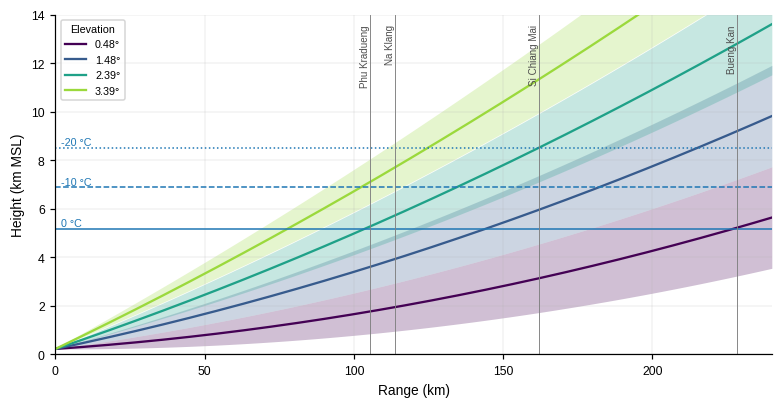

ความสูงกึ่งกลางลำคลื่น (km MSL) เหนือจุดรายงาน


,range_km,0.48°,1.48°,2.39°,3.39°
Phu Kradueng,105.2,1.8,3.6,5.3,7.1
Na Klang,113.7,1.9,3.9,5.7,7.7
Si Chiang Mai,161.9,3.1,6.0,8.5,11.3
Bueng Kan,228.4,5.2,9.2,12.8,16.8


In [7]:
r_km = np.linspace(0, 240, 241)
alt0 = meta["radar_alt_m"]
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
cols = plt.cm.viridis(np.linspace(0, 0.85, radar.nsweeps))
for e, col in zip(radar.fixed_angle["data"], cols):
    hc = pt.beam_height_km(r_km, e, alt0)
    lo, hi = pt.beam_height_km(r_km, e - 0.5, alt0), pt.beam_height_km(r_km, e + 0.5, alt0)
    ax.fill_between(r_km, lo, hi, color=col, alpha=0.25, lw=0)
    ax.plot(r_km, hc, color=col, label=f"{e:.2f}°")
for (lbl, h), ls in zip(H.items(), ("-", "--", ":")):
    ax.axhline(h / 1000, color="tab:blue", ls=ls, lw=1)
    ax.text(2, h / 1000 + 0.1, lbl, color="tab:blue", fontsize=7)
for name in ("Phu Kradueng", "Na Klang", "Si Chiang Mai", "Bueng Kan"):
    rr = kt.site(reports, name)["range_km"]
    ax.axvline(rr, color="0.5", lw=0.6)
    ax.text(rr, 13.6, name, rotation=90, fontsize=6.5, va="top", ha="right", color="0.3")
ax.set_xlim(0, 240); ax.set_ylim(0, 14)
ax.set_xlabel("Range (km)"); ax.set_ylabel("Height (km MSL)")
ax.legend(title="Elevation", loc="upper left", fontsize=7, title_fontsize=7)
ax.grid(lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb1_beam_height")
plt.show()
bt = pd.DataFrame({name: [pt.beam_height_km(kt.site(reports, name)["range_km"], e, alt0)
                          for e in radar.fixed_angle["data"]] for name in ("Phu Kradueng", "Na Klang", "Si Chiang Mai", "Bueng Kan")},
                  index=[f"{e:.2f}°" for e in radar.fixed_angle["data"]]).T
bt.insert(0, "range_km", [kt.site(reports, n)["range_km"] for n in bt.index])
print("ความสูงกึ่งกลางลำคลื่น (km MSL) เหนือจุดรายงาน")
bt.round(1)

**ข้อสังเกตสำคัญสำหรับ NB2–NB5**
- เหนือ **หนองบัวลำภู (~110–120 km)** มุมยกต่ำสุดอยู่สูง ~1.5–2 km และมุมยกสูงสุดเกือบถึงระดับ −20 °C → เห็น **ทั้งชั้นฝนและชั้นน้ำแข็ง** เหมาะกับ HID
- ที่ **บึงกาฬ (> 160 km)** มุมยกต่ำสุดเกิน 3 km → ไม่เห็นลม outflow ใกล้พื้น และกึ่งกลางลำคลื่นมุมสูงอยู่เหนือระดับเยือกแข็ง
- ลม downburst เกิดในชั้น < 1 km → **เรดาร์เห็นได้ดีเฉพาะระยะ < ~80 km** (เป็นข้อจำกัดหลักของการวิเคราะห์ใน NB2)

## ✅ 7. ตรวจคุณภาพข้อมูลเบื้องต้น
### 7.1 qc_flag: แต่ละ gate ถูกตัดเพราะอะไร
ค่า `qc_flag` เป็นผลรวมของ bit — ใช้ `np.bitwise_and(flag, bit) > 0` เพื่อดูแต่ละสาเหตุ

In [8]:
QC_BITS = {"no_echo/below floor": 1, "flare ray": 2, "non-met": 4, "speckle": 8,
           "σv invalid": 16, "V invalid": 32, "ΦDP texture high": 64}
flag = np.ma.filled(radar.fields["qc_flag"]["data"], 0).astype(int)
zr = pt.field_data(radar, "reflectivity_raw")
has_raw = np.isfinite(zr)
print(f"gate ที่มีค่า reflectivity_raw: {has_raw.sum():,}")
pd.Series({k: int(((flag & b) > 0)[has_raw].sum()) for k, b in QC_BITS.items()}, name="gates").to_frame()

gate ที่มีค่า reflectivity_raw: 76,273


,gates
no_echo/below floor,8905
flare ray,1290
non-met,8458
speckle,1191
σv invalid,20249
V invalid,20249
ΦDP texture high,2427


### 7.2 ΦDP ดิบตามแนวรัศมี: รอยพับเฟส และทิศทางที่ "กลับด้าน"

บันทึกรูปแล้ว: figures/nb1_phidp_ray.png, figures/nb1_phidp_ray.pdf


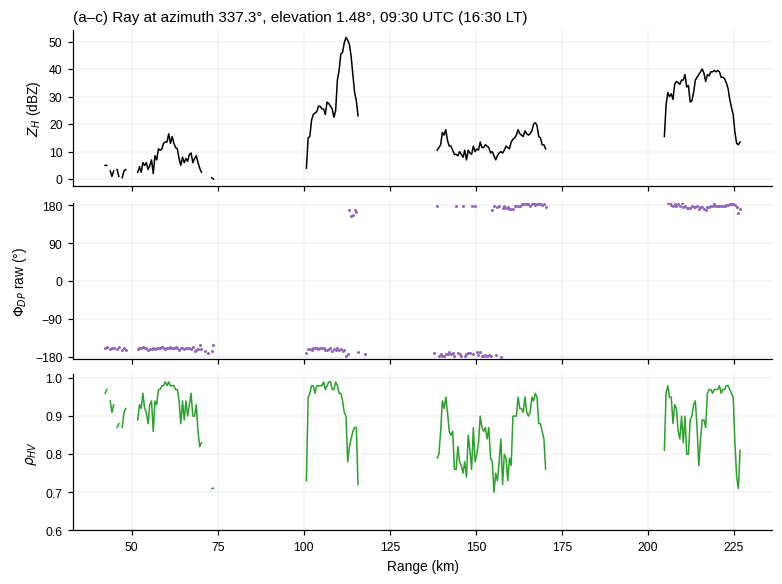

ความชันเฉลี่ยของ ΦDP (หลัง unwrap) ราย sweep [°/km, จำนวน ray]: {0: (-0.18, 4), 1: (-1.3, 12), 2: (-0.58, 16), 3: (-0.44, 9)}


In [9]:
az_nk, rng_nk = pt.azimuth_to(meta, kt.site(reports, "Na Klang")["lon"], kt.site(reports, "Na Klang")["lat"])
z0 = pt.field_data(radar, "reflectivity_qc", 1)
sl1 = radar.get_slice(1)
az1 = radar.azimuth["data"][sl1]
cand = np.where(np.abs(((az1 - az_nk) + 180) % 360 - 180) < 15)[0]
ray = cand[np.argmax(np.nansum(z0[cand] > 35, axis=1))]          # ray ที่มีแกนฝนยาวที่สุดใกล้นากลาง
rk = radar.range["data"] / 1000
fig, axs = plt.subplots(3, 1, figsize=(7, 5.2), sharex=True, layout="constrained")
axs[0].plot(rk, z0[ray], color="k", lw=1); axs[0].set_ylabel("$Z_H$ (dBZ)")
axs[1].plot(rk, pt.field_data(radar, "differential_phase_qc", 1)[ray], ".", ms=2, color="tab:purple")
axs[1].set_ylabel("$\\Phi_{DP}$ raw (°)"); axs[1].set_ylim(-185, 185); axs[1].set_yticks([-180, -90, 0, 90, 180])
axs[2].plot(rk, pt.field_data(radar, "cross_correlation_ratio_qc", 1)[ray], color="tab:green", lw=1)
axs[2].set_ylabel("$\\rho_{HV}$"); axs[2].set_ylim(0.6, 1.01); axs[2].set_xlabel("Range (km)")
for ax in axs:
    ax.grid(lw=0.3, alpha=0.5)
axs[0].set_title(f"(a–c) Ray at azimuth {az1[ray]:.1f}°, elevation 1.48°, {mp.tlabel(pt.volume_time(radar))}", loc="left")
mp.save_figure(fig, "nb1_phidp_ray")
plt.show()
slopes = pt.phidp_slope_by_sweep(radar)
print("ความชันเฉลี่ยของ ΦDP (หลัง unwrap) ราย sweep [°/km, จำนวน ray]:", {k: (round(v[0], 2), v[1]) for k, v in slopes.items()})

- เมื่อผ่านแกนฝน $\Phi_{DP}$ ของเรดาร์ทั่วไป **ควรเพิ่มขึ้น** ตามระยะ แต่ข้อมูล KKN **ลดลง** (ความชันเป็นลบ) → ต้อง **กลับเครื่องหมาย** ก่อนคำนวณ $K_{DP}$
- ค่ากระโดดจาก −180° ไป +180° คือ **รอยพับเฟส (phase wrap)** ไม่ใช่สัญญาณจริง
- ทั้งสองเรื่องจะแก้ทีละขั้นใน **NB4**

---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 1.1: PRF, ระยะไกลสุด และลมที่วัดได้
1. จาก $V_{ny}$ = 8.38 m/s และ λ ของ KKN จงคำนวณ PRF และ $r_{max}$
2. ถ้าลม downburst จริง = **+22 m/s** (ออกจากเรดาร์) เรดาร์จะวัดได้กี่ m/s? ($n$ เท่าไร?)
3. ถ้าอยากวัดลม ±30 m/s ได้โดยไม่พับ ด้วย PRF เดียว $r_{max}$ จะเหลือกี่ km?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `PRF = 4 * vny / lam`, `rmax = c / (2 * PRF)`
- หา $n$ ที่ทำให้ $V_{obs} = V_{true} - 2nV_{ny}$ อยู่ในช่วง $[-V_{ny}, V_{ny}]$: `n = np.round(v_true / (2 * vny))`

</details>

In [10]:
# ✍️ แบบฝึกหัด 1.1 — เขียนโค้ดของคุณที่นี่

In [11]:
#@title ✅ เฉลยแบบฝึกหัด 1.1
c, lam, vny = 2.998e8, pt.WAVELENGTH_M, 8.38
prf = 4 * vny / lam
print(f"1) PRF = {prf:.0f} Hz → r_max = {c / (2 * prf) / 1000:.0f} km  (ตรงกับระยะ 240 km ของข้อมูล)")
v_true = 22.0
n = np.round(v_true / (2 * vny))
print(f"2) n = {n:.0f} → V_obs = {v_true - 2 * n * vny:+.2f} m/s  (ลมออกแรง แต่เรดาร์เห็นเป็นลมเข้าเบา ๆ!)")
prf30 = 4 * 30 / lam
print(f"3) V_ny = 30 m/s ต้องใช้ PRF = {prf30:.0f} Hz → r_max = {c / (2 * prf30) / 1000:.0f} km เท่านั้น")
print("   → นี่คือ Doppler dilemma: เรดาร์ปฏิบัติการจึงเลือกวัดไกล แล้วแก้การพับด้วยซอฟต์แวร์ (NB2)")

1) PRF = 626 Hz → r_max = 239 km  (ตรงกับระยะ 240 km ของข้อมูล)
2) n = 1 → V_obs = +5.24 m/s  (ลมออกแรง แต่เรดาร์เห็นเป็นลมเข้าเบา ๆ!)
3) V_ny = 30 m/s ต้องใช้ PRF = 2241 Hz → r_max = 67 km เท่านั้น
   → นี่คือ Doppler dilemma: เรดาร์ปฏิบัติการจึงเลือกวัดไกล แล้วแก้การพับด้วยซอฟต์แวร์ (NB2)


### 🧪 แบบฝึกหัด 1.2: ประมาณ ZDR bias จากฝนเบา (8 volume ช่วงพีค)
ในฝนเบา (Z 20–28 dBZ) เม็ดฝนเล็กเกือบกลม $Z_{DR}$ จริงควรอยู่ราว **0.2 dB** ถ้าค่าที่วัดได้ต่างจากนี้ = **bias** ของระบบ
ใช้ `pt.zdr_bias_light_rain(radar, snd)` กับทั้ง 8 ไฟล์ใน `peak` แล้วสรุป bias รายมุมยก (median)

**คำถาม:** ผลใกล้กับค่าที่งานวิจัย KKN ใช้แก้ (+0.20 dB ที่มุมต่ำสุด, +0.39 dB มุมอื่น) หรือไม่? ทำไมมุมสูงจึงมี gate น้อยกว่า?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `out = pt.zdr_bias_light_rain(r, snd)` คืน dict `{sweep: (bias, n)}`
- เก็บลง list แล้ว `pd.DataFrame(rows).groupby("sweep").median()`
- ค่าที่ต้อง **บวกเพิ่ม** ให้ ZDR = −bias

</details>

In [12]:
# ✍️ แบบฝึกหัด 1.2 — เขียนโค้ดของคุณที่นี่

In [13]:
#@title ✅ เฉลยแบบฝึกหัด 1.2
rows = []
for f in peak:
    r = pt.read_volume(f)
    for s, (b, n) in pt.zdr_bias_light_rain(r, snd).items():
        rows.append({"time": pt.volume_time(r).strftime("%H:%M"), "sweep": s, "bias_dB": b, "n_gates": n})
zb = pd.DataFrame(rows)
summary = zb.groupby("sweep").agg(bias_median=("bias_dB", "median"), bias_iqr=("bias_dB", lambda x: x.quantile(.75) - x.quantile(.25)),
                                  gates_total=("n_gates", "sum"))
summary["correction_to_add"] = -summary["bias_median"]
summary["KKN_research_value"] = [pt.ZDR_CORR_BY_SWEEP[s] for s in summary.index]
print(summary.round(2))
print("\n→ มุมสูงมี gate น้อย เพราะฝนเบาที่ต่ำกว่าระดับ 0 °C − 1 km อยู่ใกล้เรดาร์เท่านั้น (ลำคลื่นมุมสูงทะลุชั้นฝนเร็ว)")
print("  ค่าที่ได้เปลี่ยนตามเวลา/ตัวอย่าง → งานวิจัยจริงควรประมาณจากหลายวัน หรือใช้ birdbath/vertical-pointing scan")

       bias_median  bias_iqr  gates_total  correction_to_add  \
sweep                                                          
0            -0.20      0.19        11383               0.20   
1            -0.20      0.11         8951               0.20   
2            -0.24      0.11         3128               0.24   
3            -0.39      0.03         1494               0.39   

       KKN_research_value  
sweep                      
0                    0.20  
1                    0.39  
2                    0.39  
3                    0.39  

→ มุมสูงมี gate น้อย เพราะฝนเบาที่ต่ำกว่าระดับ 0 °C − 1 km อยู่ใกล้เรดาร์เท่านั้น (ลำคลื่นมุมสูงทะลุชั้นฝนเร็ว)
  ค่าที่ได้เปลี่ยนตามเวลา/ตัวอย่าง → งานวิจัยจริงควรประมาณจากหลายวัน หรือใช้ birdbath/vertical-pointing scan


### 🧪 แบบฝึกหัด 1.3: ρHV ลดลงตามระยะหรือไม่?
เลือก gate ที่เป็นฝนแน่ ๆ (Z ≥ 35 dBZ, ต่ำกว่าระดับ 0 °C) จากมุมยก 0.48° ของ 8 volume
แล้วหา **median ของ $\rho_{HV}$ ทุกช่วงระยะ 20 km** พลอตกราฟ ρHV–ระยะ

**คำถาม:** ถ้า ρHV ลดลงตามระยะ จะมีผลอย่างไรกับการจำแนกหยาดน้ำฟ้า (NB5)? สาเหตุทางกายภาพคืออะไร?

<details>
<summary><b>💡 คำใบ้</b></summary>

- ระยะของ gate: `np.broadcast_to(r.range["data"] / 1000, (nrays, ngates))`
- ความสูง gate: `r.gate_altitude["data"]`
- `pd.cut(range_km, np.arange(0, 241, 20))` แล้ว `groupby(...).median()`

</details>

In [14]:
# ✍️ แบบฝึกหัด 1.3 — เขียนโค้ดของคุณที่นี่

บันทึกรูปแล้ว: figures/nb1_ex13_rhohv_range.png, figures/nb1_ex13_rhohv_range.pdf


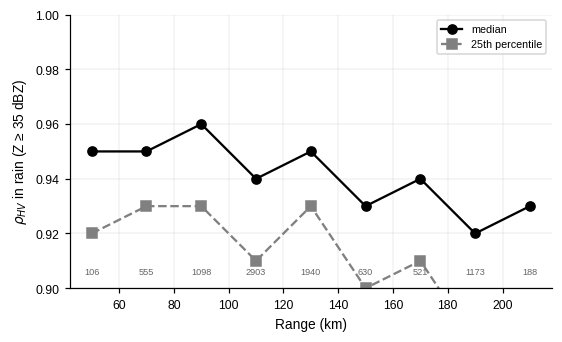

            median  count   p25
bin                            
(40, 60]      0.95    106  0.92
(60, 80]      0.95    555  0.93
(80, 100]     0.96   1098  0.93
(100, 120]    0.94   2903  0.91
(120, 140]    0.95   1940  0.93
(140, 160]    0.93    630  0.90
(160, 180]    0.94    521  0.91
(180, 200]    0.92   1173  0.88
(200, 220]    0.93    188  0.89

→ median ρHV ช่วง 40–120 km ≈ 0.950 และช่วง 160–220 km ≈ 0.930: ลดลงเล็กน้อยตามระยะ
  สาเหตุ: ลำคลื่นกว้างขึ้น (non-uniform beam filling), SNR ต่ำลง และลำคลื่นเข้าใกล้ชั้นละลาย
  ข้อสังเกต: ρHV ในฝนของ KKN (~0.95) ต่ำกว่าทฤษฎี (> 0.98) ทั้งช่วง → เป็นลักษณะของระบบ/การประมวลผลสัญญาณ ต้องระวังเมื่อใช้เกณฑ์จากต่างประเทศ
  ผลต่อ HID: ฝนที่ระยะไกลอาจถูกจัดเป็นคลาสที่มี ρHV ต่ำ (เช่น WS/MH) → ต้องระวังเมื่อแปลผลที่ระยะ > 150 km


In [15]:
#@title ✅ เฉลยแบบฝึกหัด 1.3
recs = []
for f in peak:
    r = pt.read_volume(f)
    sl = r.get_slice(0)
    z = pt.field_data(r, "reflectivity_qc", 0)
    rho = pt.field_data(r, "cross_correlation_ratio_qc", 0)
    alt = r.gate_altitude["data"][sl]
    rr = np.broadcast_to(r.range["data"] / 1000, z.shape)
    m = (z >= 35) & np.isfinite(rho) & (alt < H["0 °C"] - 500)
    recs.append(pd.DataFrame({"range_km": rr[m], "rho": rho[m]}))
rh = pd.concat(recs)
rh["bin"] = pd.cut(rh["range_km"], np.arange(0, 241, 20))
g = rh.groupby("bin", observed=True)["rho"].agg(["median", "count", lambda x: x.quantile(0.25)])
g.columns = ["median", "count", "p25"]
mid = [b.mid for b in g.index]
fig, ax = plt.subplots(figsize=(5, 3), layout="constrained")
ax.plot(mid, g["median"], "o-", color="k", label="median")
ax.plot(mid, g["p25"], "s--", color="0.5", label="25th percentile")
for x_, n_ in zip(mid, g["count"]):
    ax.text(x_, 0.905, f"{n_}", fontsize=6, ha="center", color="0.4")
ax.set_xlabel("Range (km)"); ax.set_ylabel("$\\rho_{HV}$ in rain (Z ≥ 35 dBZ)"); ax.set_ylim(0.9, 1.0)
ax.legend(fontsize=7); ax.grid(lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb1_ex13_rhohv_range")
plt.show()
print(g.round(3))
near_, far_ = g["median"].iloc[:4].mean(), g["median"].iloc[-3:].mean()
print(f"\n→ median ρHV ช่วง 40–120 km ≈ {near_:.3f} และช่วง 160–220 km ≈ {far_:.3f}: ลดลงเล็กน้อยตามระยะ")
print("  สาเหตุ: ลำคลื่นกว้างขึ้น (non-uniform beam filling), SNR ต่ำลง และลำคลื่นเข้าใกล้ชั้นละลาย")
print("  ข้อสังเกต: ρHV ในฝนของ KKN (~0.95) ต่ำกว่าทฤษฎี (> 0.98) ทั้งช่วง → เป็นลักษณะของระบบ/การประมวลผลสัญญาณ ต้องระวังเมื่อใช้เกณฑ์จากต่างประเทศ")
print("  ผลต่อ HID: ฝนที่ระยะไกลอาจถูกจัดเป็นคลาสที่มี ρHV ต่ำ (เช่น WS/MH) → ต้องระวังเมื่อแปลผลที่ระยะ > 150 km")

---
## 📝 สรุป
- ข้อมูล polar ของ KKN มี **4 มุมยก × ~511 ray × 480 gate** ต่อ volume และมีตัวแปร 6 ชนิดที่บอกเรื่องต่างกัน
- $V_{ny}$ ช่วงพายุเพียง **8.38 m/s** (PRF ~630 Hz เพื่อวัดไกล 240 km) → **ลมแรงพับแน่นอน** ต้องแก้ใน NB2
- ที่หนองบัวลำภู ลำคลื่นต่ำสุดอยู่สูง ~1.5–2 km และมุมสูงสุดเข้าใกล้ระดับ −20 °C → เห็นโครงสร้างแนวตั้งพอสำหรับ HID แต่ **เห็น outflow ใกล้พื้นได้จำกัด**
- ข้อมูล dual-pol ต้องเตรียมก่อนใช้: **ZDR มี bias**, **ΦDP พับเฟสและกลับเครื่องหมาย**, **ρHV ลดลงตามระยะ**

### ❓ คำถามชวนคิด
1. ช่วงเช้า $V_{ny}$ = 16.75 m/s (2 เท่า) แต่ข้อมูลยังไปถึง 240 km — เป็นไปได้อย่างไร? (คำใบ้: dual-PRF / staggered PRT) แล้วมีข้อเสียอะไร?
2. ถ้าต้องการศึกษา downburst ที่ภูกระดึง (~90 km) เรดาร์ KKN มีข้อจำกัดอะไร? ข้อมูลอื่นที่ช่วยได้คืออะไร (เช่น สถานีตรวจอากาศอัตโนมัติ, เรดาร์อื่น)?
3. sounding ที่ใช้เป็นเวลา 00Z (07:00 น.) ก่อนพายุ 7–10 ชั่วโมง ระดับ 0 °C ตอนบ่ายน่าจะต่างไปอย่างไร และกระทบ HID อย่างไร?

**🚀 ต่อยอด (ป.โท):** ทำแบบฝึกหัด 1.2 กับข้อมูลทั้งวัน (92 volume) แล้วพลอต ZDR bias ตามเวลา — bias คงที่หรือเปลี่ยนตามอุณหภูมิของเครื่อง/เวลา?

### 📚 เอกสารอ้างอิง
- Doviak, R. J., & Zrnić, D. S. (1993). *Doppler Radar and Weather Observations* (2nd ed.). Academic Press.
- Rinehart, R. E. (2010). *Radar for Meteorologists* (5th ed.). Rinehart Publications.
- Kumjian, M. R. (2013). Principles and applications of dual-polarization weather radar. Parts I–III. *J. Operational Meteor.*, 1, 226–274.
- Helmus, J. J., & Collis, S. M. (2016). The Python ARM Radar Toolkit (Py-ART). *J. Open Research Software*, 4, e25.
- Ryzhkov, A. V., & Zrnić, D. S. (2019). *Radar Polarimetry for Weather Observations*. Springer.